
### Miniproyecto 3 - IA en Dispositivos Móviles y Embebidos

### Estudiantes:
Nicole Valeria Ruiz Valencia - 2240429

Alessandro Yusty Ceballos - 2240248

Robinson Bastidas Buitrago - 22235994

---------------------------------------------------------------------

* NVIDIA Jetson Nano 4GB con JetPack 4.6.1 (TensorRT 8.2)

* **5 Clases del proyecto:**
  1. `0: capacitor_electrolitico`
  2. `1: dip_switch`
  3. `2: resistencia_ceramica`
  4. `3: switch_de_dos_patas`
  5. `4: trimmer`

Este notebook contiene:

1. Importación e instalación de liberías
2. Descompresión y corrección automática del data.yaml del ZIP de Roboflow.
3. Entrenamiento de YOLOv8n con Transfer Learning.
4. Extracción de métricas, matriz de confusión y curvas de pérdida para el informe IEEE.
5. Inferencia visual en imágenes de test.
6. Exportación optimizada a ONNX con opset=12 (100% compatible con JetPack 4.6.1).


# 1. Importar e instalar librerías

In [ ]:

!pip install --quiet ultralytics onnx onnxruntime onnxsim pyyaml matplotlib opencv-python
import os
import glob
import zipfile
import yaml
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import Image, display

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
✅ Librerías importadas correctamente.


## 2. Preparación Automática del Dataset
Subir el archivo del dataset formateado para YOLOv8

(Electronic_Component_Sorting.v1-yolov8-export.yolov8.zip )

1. Detectar y descomprimir el archivo ZIP.
2. Corregir las rutas relativas de Roboflow (../train/images rutas absolutas).
3. Resumen de clases y número de imágenes por partición.



In [ ]:
# Buscar el archivo zip
zip_files = glob.glob("*.zip")
if not zip_files:
    raise FileNotFoundError("No se encontró  el archivo en /content. Suba el archivo ZIP a Colab y vuelva a ejecutar esta celda.")

zip_path = zip_files[0]
extract_dir = "/content/dataset_componentes"

print(f"Descomprimiendo: {zip_path} en {extract_dir}...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

# Localizar y corregir data.yaml
yaml_files = glob.glob(f"{extract_dir}/**/data.yaml", recursive=True)

yaml_path = yaml_files[0]
dataset_root = os.path.dirname(yaml_path)

with open(yaml_path, 'r') as f:
    config = yaml.safe_load(f)

# Corregir rutas relativas para evitar FileNotFoundError en Ultralytics
config['path'] = os.path.abspath(dataset_root)
config['train'] = 'train/images'
config['val'] = 'valid/images'
config['test'] = 'test/images'

with open(yaml_path, 'w') as f:
    yaml.dump(config, f, sort_keys=False)

print("Dataset configurado con éxito:")
print(f"   Ruta base: {config['path']}")
print(f"   Clases ({len(config['names'])}): {config['names']}")

# Contar imágenes disponibles
for split in ['train', 'valid', 'test']:
    imgs = glob.glob(os.path.join(dataset_root, split, 'images', '*.*'))
    print(f"   Imágenes en {split}: {len(imgs)}")


Descomprimiendo: Electronic Component Sorting.v1-yolov8-export.yolov8.zip en /content/dataset_componentes...
Dataset configurado con éxito:
   Ruta base: /content/dataset_componentes
   Clases (5): ['capacitor_electrolitico', 'dip_switch', 'resistencia_ceramica', 'switch_de_dos_patas', 'trimmer']
   Imágenes en train: 97
   Imágenes en valid: 28
   Imágenes en test: 14


## 3. Entrenamiento del Modelo YOLOv8n
* **Modelo base:** yolov8n.pt (versión Nano, ligera y rápida para la GPU Maxwell de la Jetson Nano).
* **imgsz=640:** Resolución estándar balanceada entre detalle y velocidad.
* **epochs=60:** Con early stopping (patience=15) para evitar sobreajuste.


In [ ]:
# Cargar pesos preentrenados de YOLOv8 Nano
model = YOLO('yolov8n.pt')

# Iniciar entrenamiento
results = model.train(
    data=yaml_path,
    epochs=60,
    imgsz=640,
    batch=16,
    patience=15,
    device=0,
    project='proyecto_embebidos',
    name='yolov8n_componentes',
    save=True,
    verbose=True
)


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_componentes/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_componentes, nbs=64, nms=None, opset=None

## 4. Métricas



Carpeta de resultados: /content/runs/detect/proyecto_embebidos/yolov8n_componentes
Curvas de entrenamiento y pérdidas:


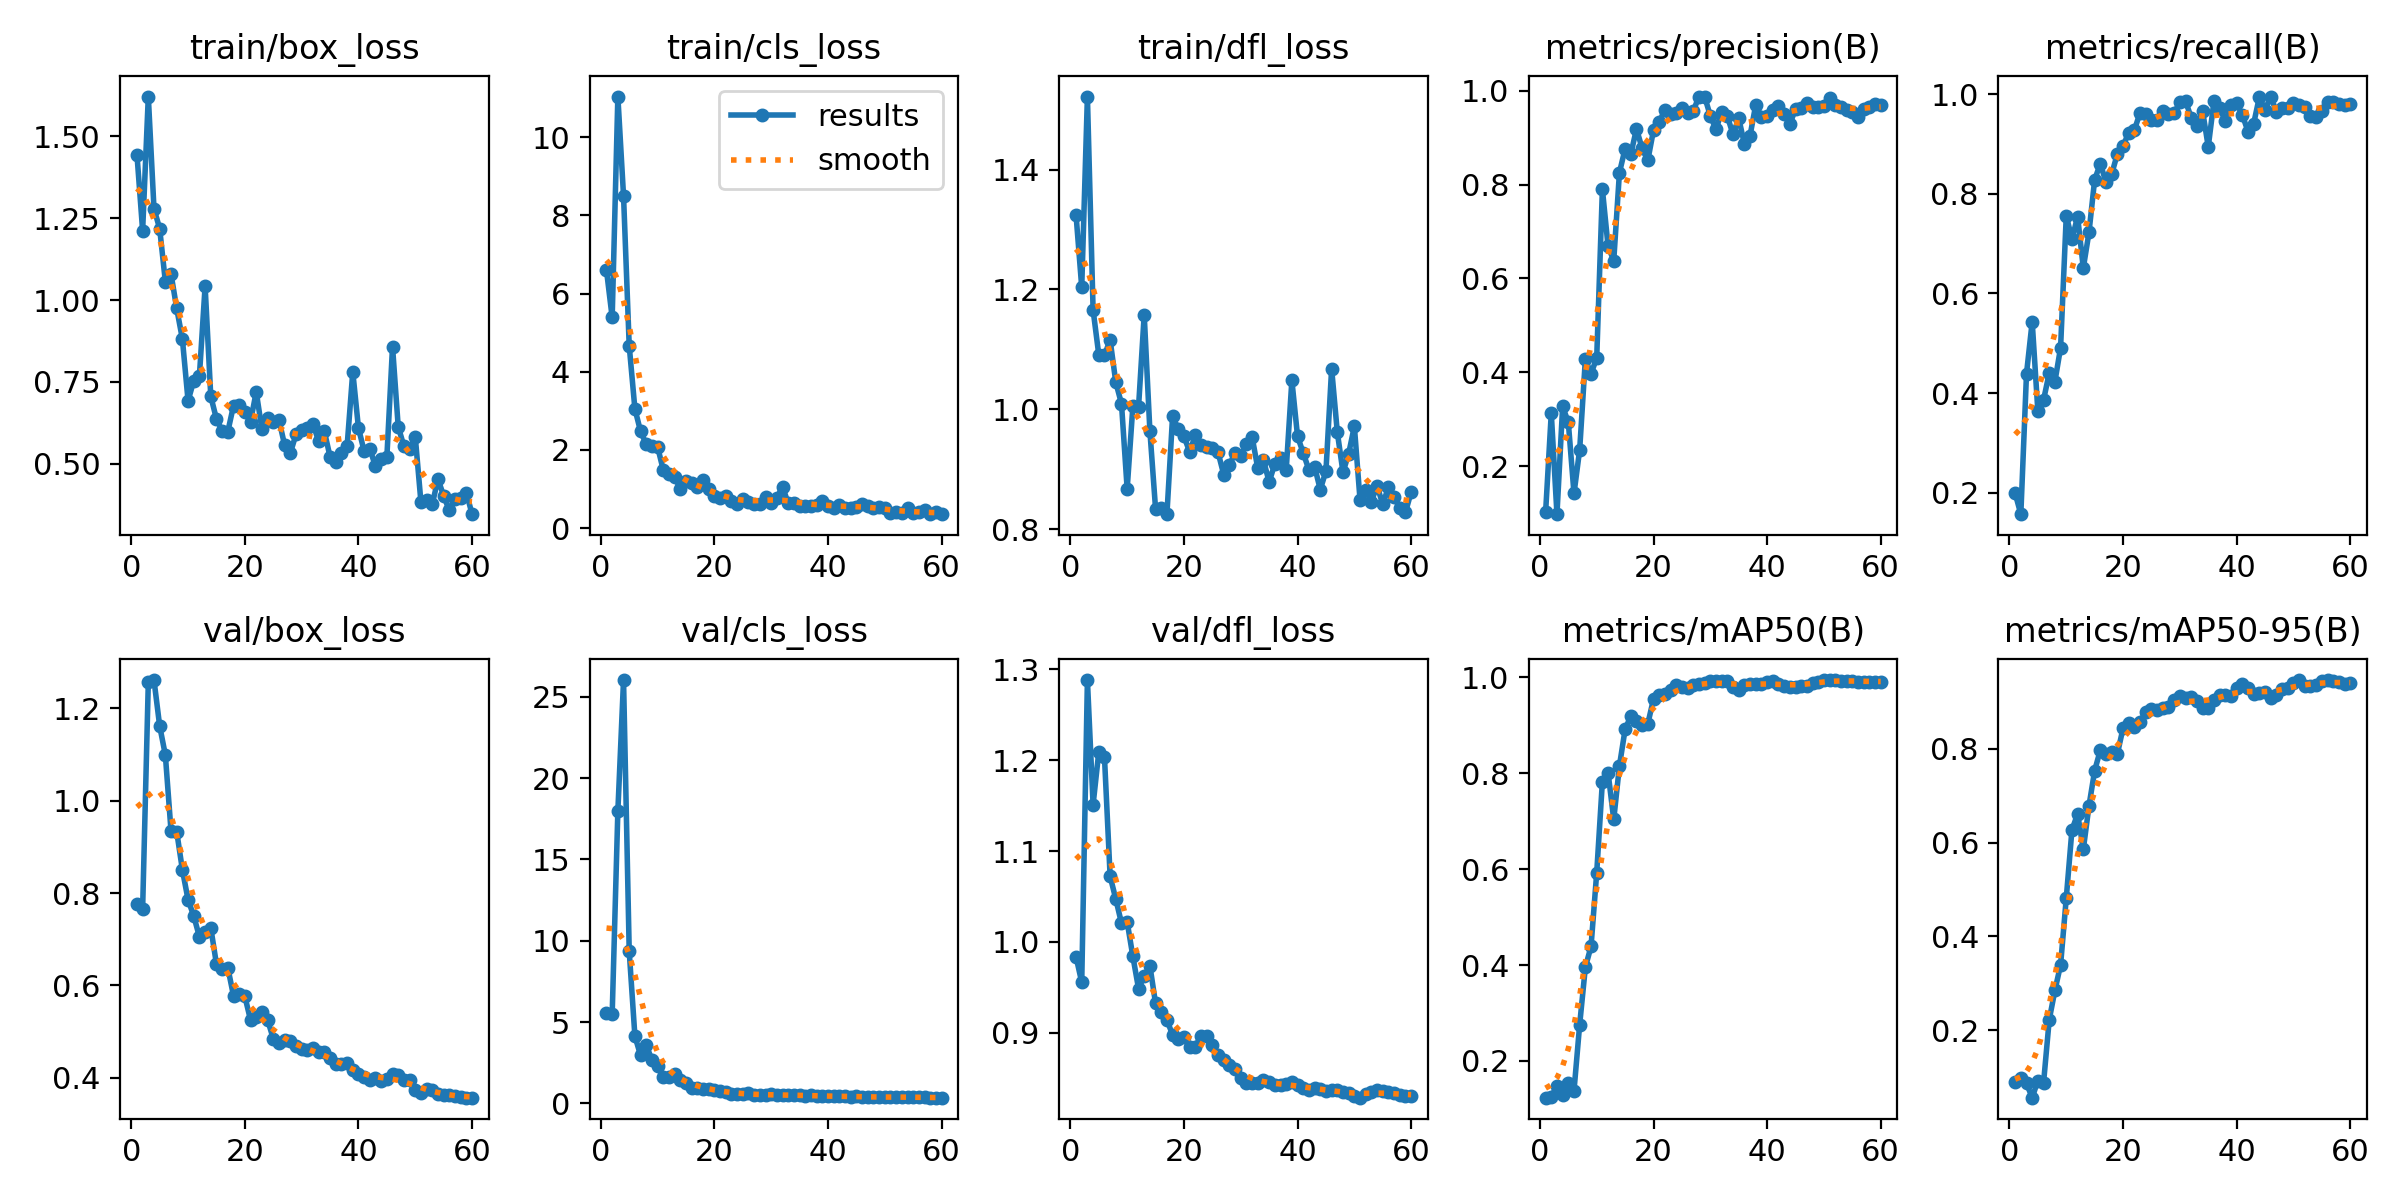

Matriz de Confusión:


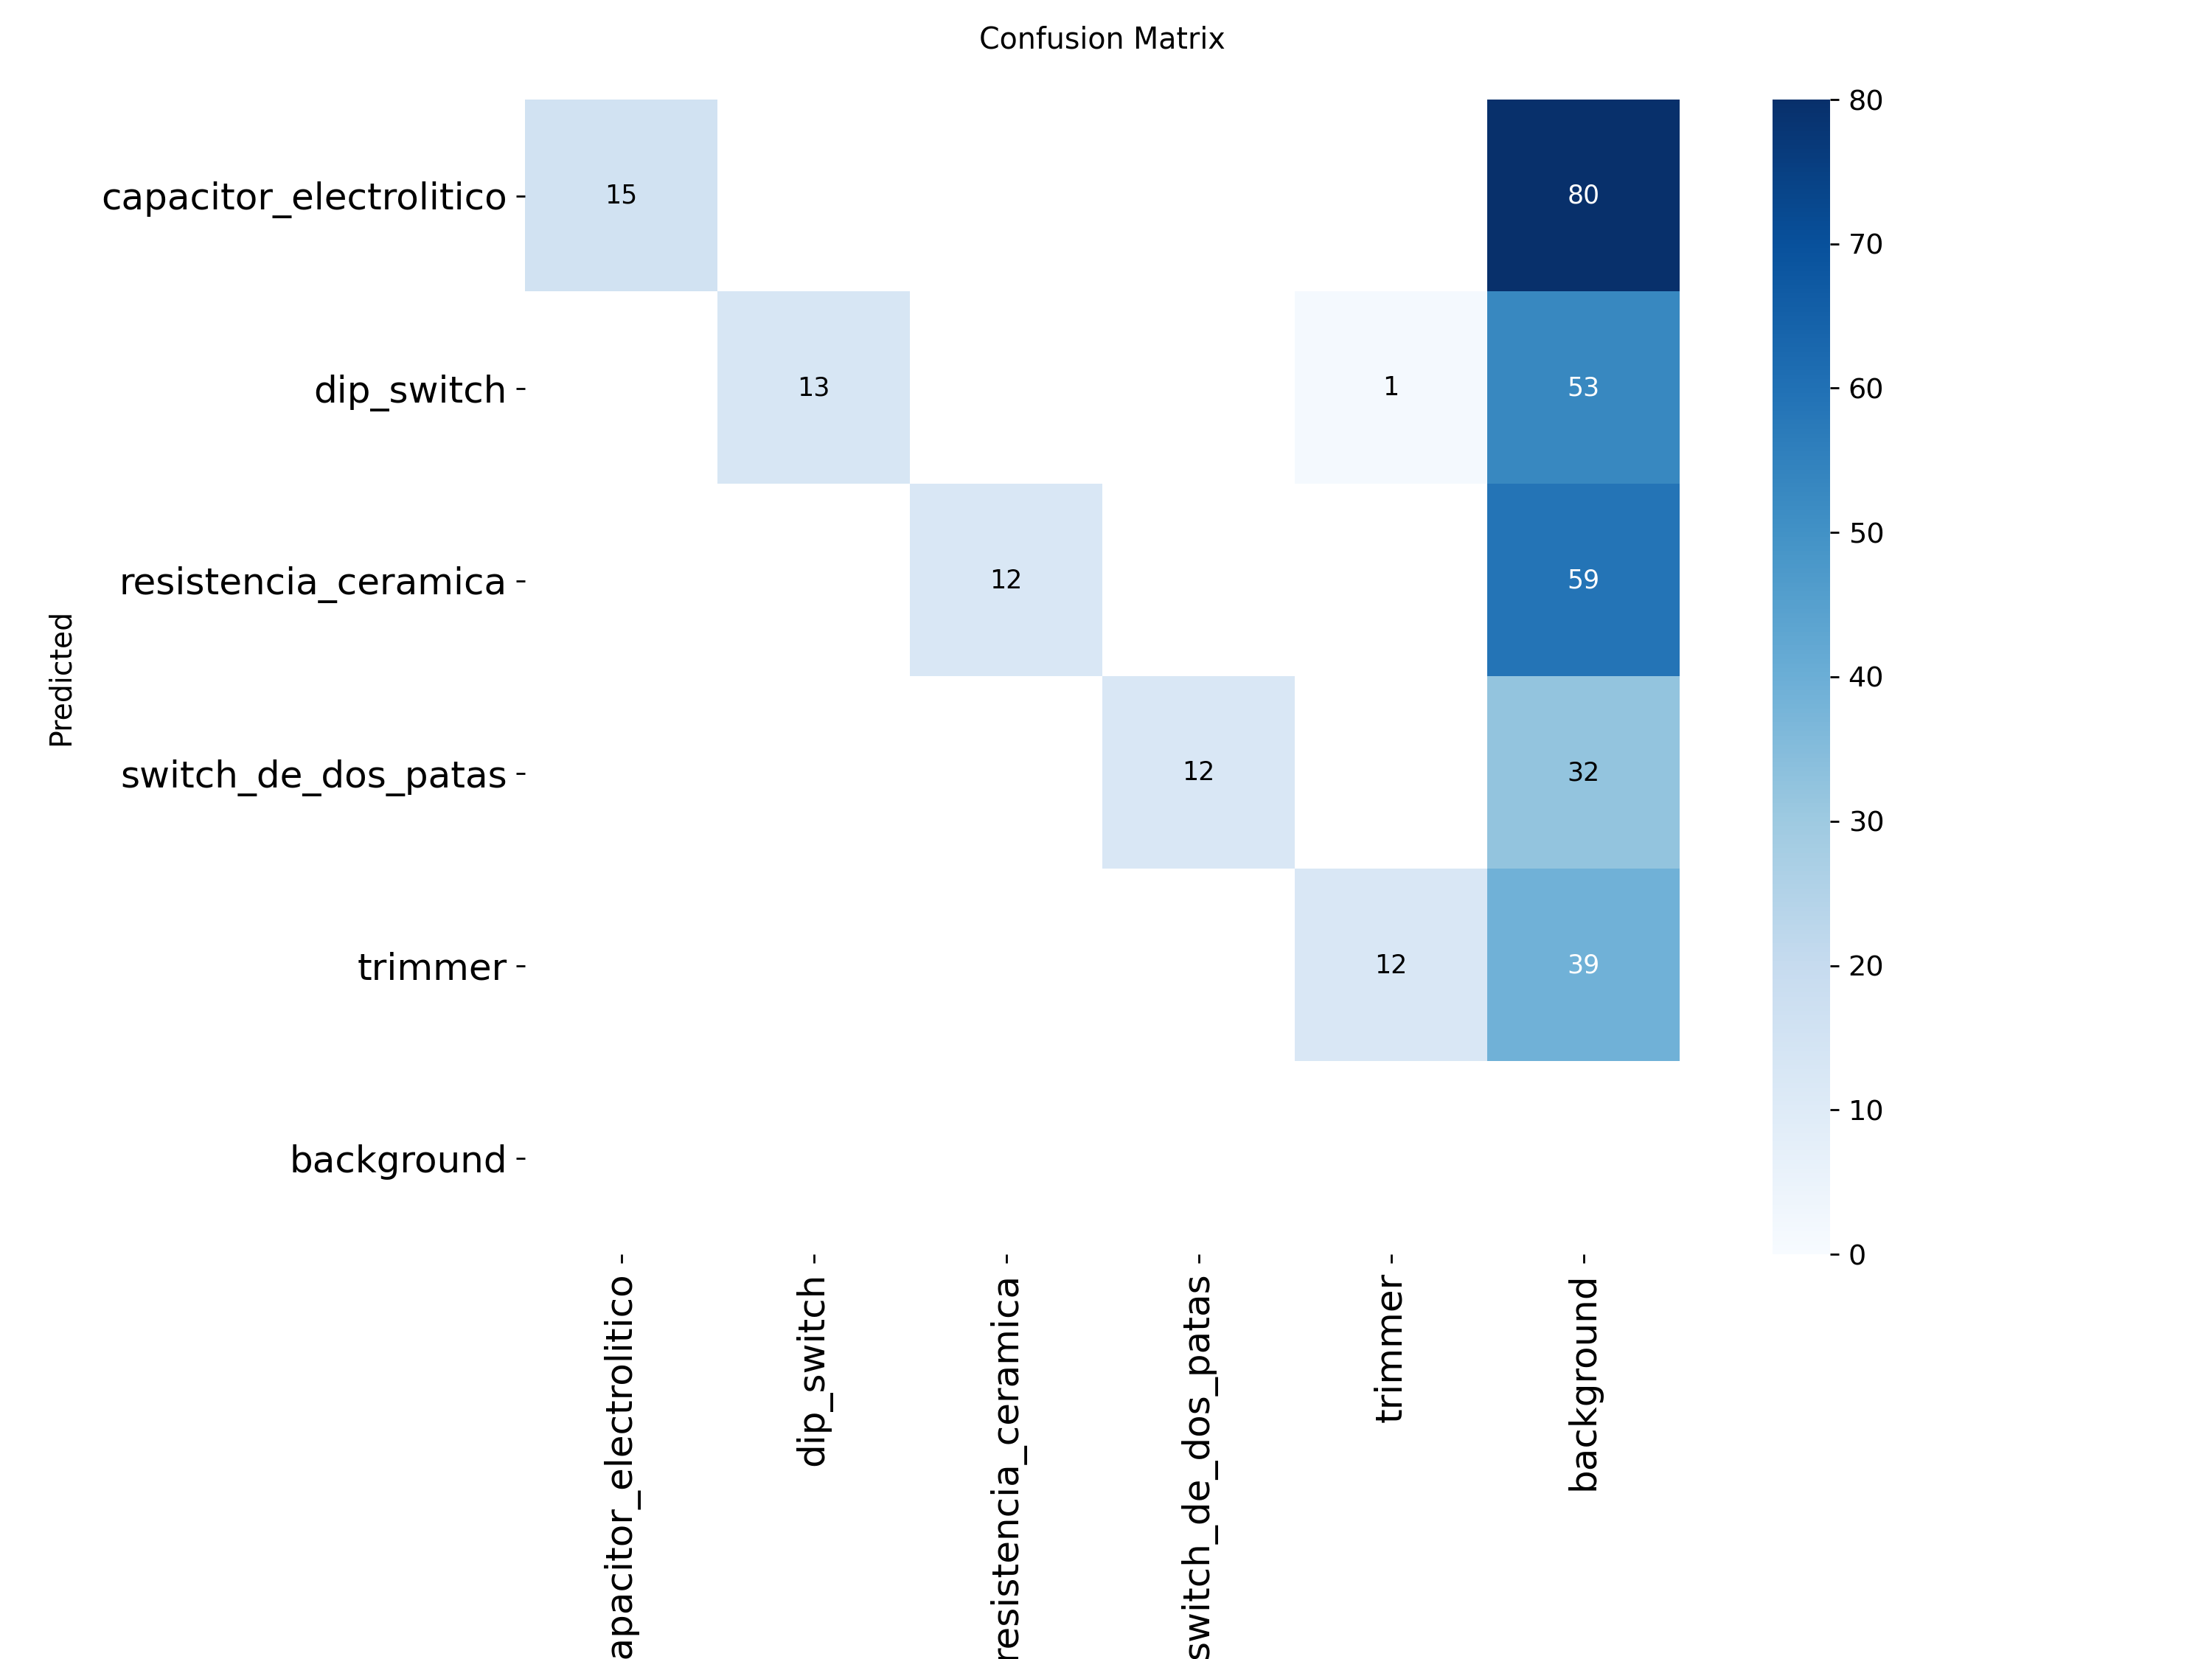

In [ ]:
# Carpeta donde se guardaron los resultados del entrenamiento actual
save_dir = str(model.trainer.save_dir)
print(f"Carpeta de resultados: {save_dir}")

matriz_conf = os.path.join(save_dir, 'confusion_matrix.png')
curvas_resultados = os.path.join(save_dir, 'results.png')

if os.path.exists(curvas_resultados):
    print("Curvas de entrenamiento y pérdidas:")
    display(Image(filename=curvas_resultados))

if os.path.exists(matriz_conf):
    print("Matriz de Confusión:")
    display(Image(filename=matriz_conf))


In [ ]:
# Evaluación en el conjunto de prueba (Test split)
metrics = model.val(split='test')

print("" + "="*50)
print(f"mAP@50 global:    {metrics.box.map50:.4f}")
print(f"mAP@50-95 global: {metrics.box.map:.4f}")
print("="*50)

# Métricas por clase
class_names = config['names']
if isinstance(class_names, dict):
    class_names = [class_names[k] for k in sorted(class_names.keys())]

print(f"{'Clase':<30} | {'mAP@50':<10}")
print("-" * 45)
for i, name in enumerate(class_names):
    map_val = metrics.box.maps[i] if i < len(metrics.box.maps) else 0.0
    print(f"{name:<30} | {map_val:.4f}")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 600.8±148.2 MB/s, size: 12.6 KB)
val: Scanning /content/dataset_componentes/test/labels... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 2.0Kit/s 0.0s
val: New cache created: /content/dataset_componentes/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.8it/s 0.2s
                   all         14         32      0.989      0.979      0.995      0.909
capacitor_electrolitico          4          4      0.982          1      0.995      0.769
            dip_switch         10         10      0.991          1      0.995      0.913
  resistencia_ceramica          6          6          1      0.897      0.995      0.971
   switch_de_dos_patas          5          5      0.986          1 

## 5. Inferencia Visual en Imágenes de Test



0: 640x640 1 resistencia_ceramica, 6.4ms
1: 640x640 1 resistencia_ceramica, 6.4ms
2: 640x640 1 capacitor_electrolitico, 1 dip_switch, 1 resistencia_ceramica, 1 switch_de_dos_patas, 1 trimmer, 6.4ms
3: 640x640 1 capacitor_electrolitico, 1 dip_switch, 1 resistencia_ceramica, 1 switch_de_dos_patas, 1 trimmer, 6.4ms
Speed: 2.8ms preprocess, 6.4ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


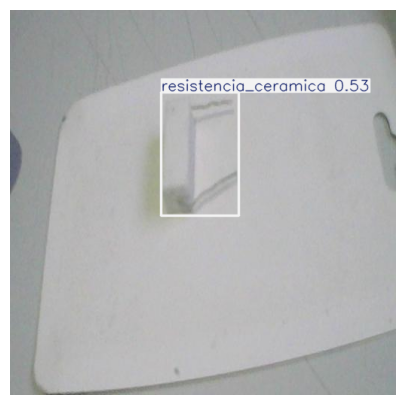

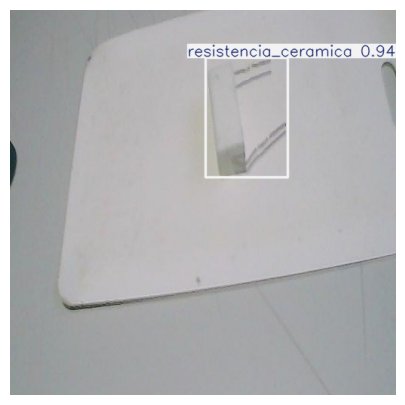

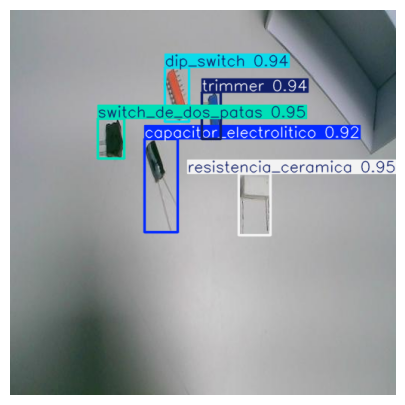

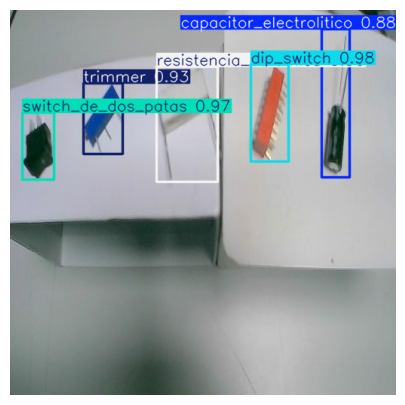

In [ ]:
test_images = glob.glob(os.path.join(dataset_root, 'test', 'images', '*.*'))

if test_images:
    sample_imgs = test_images[:min(4, len(test_images))]
    preds = model(sample_imgs, conf=0.35)

    for r in preds:
        im_bgr = r.plot()
        im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(7, 5))
        plt.imshow(im_rgb)
        plt.axis('off')
        plt.show()
else:
    print("No se encontraron imágenes en la partición de test.")


## 6.Exportación Crítica para Jetson Nano (JetPack 4.6.1)
### Parámetros Esenciales:
* **opset=12**: Requisito indispensable. TensorRT 8.2 en JetPack 4.6.1 no soporta opsets superiores (17/18).

* **simplify=True**: Elimina nodos y operaciones redundantes del grafo ONNX.

* Exportamos directamente desde el modelo en memoria o sus mejores pesos (best.pt).


In [ ]:
# Exportar el modelo entrenado a formato ONNX optimizado
onnx_file = model.export(
    format="onnx",
    opset=12,        # por compatibilidad
    simplify=True,
    imgsz=640
)

print(f"Modelo ONNX generado exitosamente en: {onnx_file}")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/runs/detect/proyecto_embebidos/yolov8n_componentes/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 9, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 220ms
Prepared 2 packages in 33ms
Installed 2 packages in 5ms
 + colorama==0.4.6
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.2s, 

In [ ]:
# Descargar automáticamente el archivo best.onnx
from google.colab import files
files.download(onnx_file)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Despliegue en la Jetson Nano
Pase el archivo best.onnx a la Jetson Nano y ejecute el siguiente comando en la terminal de la Jetson:

----------------------------------------------------
### Compilar el motor TensorRT acelerado con FP16:
/usr/src/tensorrt/bin/trtexec \
    --onnx=best.onnx \
    --saveEngine=best.engine \
    --fp16 \
    --workspace=1024

